/home/impasse/Dev/vod-assistant/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


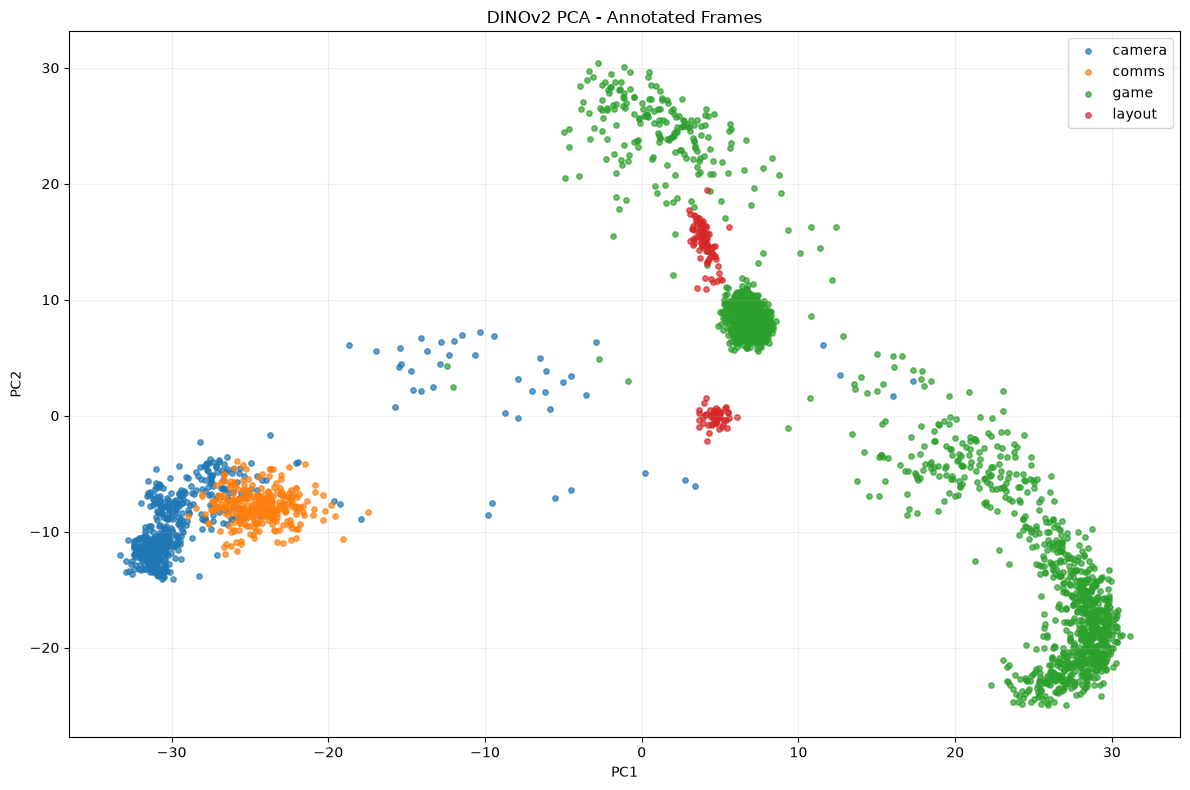

In [1]:
from pathlib import Path
from main import load_timestamps
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd

import sys

dest = "./output/genesis_x3_top64_ssbu"
## Load embeddings
feats = np.load(dest + ".npy")


# Project ALL embeddings together
pca = PCA(n_components=2)
feats_2d = pca.fit_transform(feats)

# Assign labels to every sampled frame
labels = np.full(len(feats), "unknown", dtype=object)

fps_original = 30000 / 1001
ts_path = Path("./data/genesis_x3_top64_ssbu.mp4.csv")
df = load_timestamps(ts_path, fps_original)
for _, row in df.iterrows():
    start = int(row["Start"])
    end = int(row["End"])

    start = max(0, start)
    end = min(len(feats), end)

    labels[start:end] = row["Name"]

# Create dataframe
results = pd.DataFrame(
    {
        "second": np.arange(len(feats)),
        "PC1": feats_2d[:, 0],
        "PC2": feats_2d[:, 1],
        "label": labels,
    }
)

# Exclude unknown labels
plot_data = results[results["label"] != "unknown"]

fig, ax = plt.subplots(figsize=(12, 8))

for label, group in plot_data.groupby("label"):
    ax.scatter(group["PC1"], group["PC2"], label=label, s=15, alpha=0.7)

ax.set_title("DINOv2 PCA - Annotated Frames")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()